# Stage 4 – Monitoring

**Input:** `data/processed/scores.parquet` (the PD of every model for every loan) and `data/processed/loans_clean.parquet` (the features).

**Output:** `data/processed/monitoring.csv` with three tests per quarter and model, `data/processed/psi_features.csv`, and four figures.

This stage answers the **when**: each of the 16 quarters from 2012Q1 to 2015Q4 is treated as a new cohort arriving at the bank, and the three frozen models are checked on it exactly as in a validation report:

| Test | Question | Green | Amber | Red |
| --- | --- | --- | --- | --- |
| Discrimination (Gini) | Does the model still rank good and bad borrowers? | drop < 5% | 5-10% | > 10% |
| Calibration | Is the predicted default rate close to the observed one? | gap < 10% | 10-25% | > 25% |
| Stability (PSI of the score) | Has the scored population changed? | < 0.10 | 0.10-0.25 | > 0.25 |

The PSI thresholds are an industry convention. The Gini and calibration thresholds are a choice of this project.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from scipy.stats import binomtest

from helpers import (BLUES, DEV_YEARS, FEATURES, FIGURES, INK, INK_MUTED, INK_SOFT, LIGHT_COLORS,
                     MODEL_COLORS, MODEL_LABELS, PROCESSED, bootstrap_gini, label_quarters, psi,
                     set_plot_style, traffic_light)

set_plot_style()

scores = pd.read_parquet(PROCESSED / "scores.parquet")
loans = pd.read_parquet(PROCESSED / "loans_clean.parquet")

MODEL_NAMES = list(MODEL_LABELS)
# Amber and red limits of every test.
THRESHOLDS = {"gini": (0.05, 0.10), "calibration": (0.10, 0.25), "psi": (0.10, 0.25)}

holdout = scores[scores["sample"] == "holdout"]
monitoring = scores[scores["sample"] == "monitoring"]
quarters = sorted(monitoring["issue_quarter"].unique())
print(f"{len(quarters)} quarters, from {quarters[0]} to {quarters[-1]}, {len(monitoring):,} loans")

16 quarters, from 2012Q1 to 2015Q4, 182,967 loans


## 1. The reference: performance at development

Every test compares a quarter with the development sample. The reference is the **holdout** (the 20% of the 2009-2011 loans that the models never saw), not the training loans: on the training loans XGBoost looks better than it really is, and every later quarter would seem a decline.

The interval is a 95% bootstrap interval. It is wide, because the holdout has only about 5,700 loans: the reference itself is known with some uncertainty.

In [2]:
reference = pd.DataFrame(
    [bootstrap_gini(holdout["target"], holdout[model]) for model in MODEL_NAMES],
    index=MODEL_NAMES, columns=["gini", "gini_low", "gini_high"],
)
reference.round(4)

,gini,gini_low,gini_high
pd_logit,0.3884,0.3418,0.4347
pd_xgb,0.4043,0.3598,0.4503
pd_grade,0.3125,0.2656,0.3462


## 2. Three tests for every quarter and model

For each cohort:

- **Gini** with a 95% bootstrap interval (200 resamples), and its relative drop from the reference.
- **Calibration**: mean PD against the observed default rate. The gap is `default rate / mean PD - 1`, so a positive gap means the model underestimates risk. The binomial test is reported for information only: with 12,000 loans it rejects even tiny gaps, so the traffic light uses the size of the gap.
- **PSI** of the score against the holdout, on the ten deciles of the holdout.

In [3]:
rows = []
for quarter in quarters:
    cohort = monitoring[monitoring["issue_quarter"] == quarter]
    loans_count, defaults = len(cohort), int(cohort["target"].sum())
    default_rate = defaults / loans_count
    for model in MODEL_NAMES:
        gini_value, gini_low, gini_high = bootstrap_gini(cohort["target"], cohort[model])
        mean_pd = cohort[model].mean()
        rows.append({
            "issue_quarter": quarter, "model": model, "loans": loans_count, "defaults": defaults,
            "auc": (gini_value + 1) / 2,
            "gini": gini_value, "gini_low": gini_low, "gini_high": gini_high,
            "gini_drop": 1 - gini_value / reference.loc[model, "gini"],
            "mean_pd": mean_pd, "default_rate": default_rate,
            "calibration_gap": default_rate / mean_pd - 1,
            "binomial_p": binomtest(defaults, loans_count, mean_pd).pvalue,
            "psi": psi(holdout[model], cohort[model]),
        })
results = pd.DataFrame(rows)

results["gini_light"] = results["gini_drop"].apply(traffic_light, args=THRESHOLDS["gini"])
results["calibration_light"] = results["calibration_gap"].abs().apply(traffic_light, args=THRESHOLDS["calibration"])
results["psi_light"] = results["psi"].apply(traffic_light, args=THRESHOLDS["psi"])
results.to_csv(PROCESSED / "monitoring.csv", index=False)

for model in MODEL_NAMES:
    print(f"\n{MODEL_LABELS[model]}")
    columns = ["issue_quarter", "gini", "gini_low", "gini_high", "gini_drop", "mean_pd", "default_rate",
               "calibration_gap", "psi", "gini_light", "calibration_light", "psi_light"]
    print(results.loc[results["model"] == model, columns].round(3).to_string(index=False))


Logistic regression
issue_quarter  gini  gini_low  gini_high  gini_drop  mean_pd  default_rate  calibration_gap   psi gini_light calibration_light psi_light
       2012Q1 0.295     0.260      0.337      0.241    0.114         0.132            0.157 0.044        red             amber     green
       2012Q2 0.307     0.273      0.335      0.210    0.120         0.142            0.184 0.064        red             amber     green
       2012Q3 0.322     0.292      0.347      0.172    0.126         0.141            0.123 0.138        red             amber     amber
       2012Q4 0.267     0.238      0.296      0.312    0.129         0.127           -0.015 0.200        red             green     amber
       2013Q1 0.297     0.272      0.324      0.235    0.133         0.128           -0.031 0.230        red             green     amber
       2013Q2 0.293     0.268      0.320      0.246    0.131         0.129           -0.015 0.207        red             green     amber
       2013Q3 0.247 

## 3. When does each model turn amber or red?

The answer to the first half of the research question. For each model and test: the first quarter that is not green, the first red quarter, and how many of the 16 quarters fall in each colour.

In [4]:
def first_quarter(is_true):
    return is_true.idxmax() if is_true.any() else "never"


summary = []
for model in MODEL_NAMES:
    for test in THRESHOLDS:
        lights = results[results["model"] == model].set_index("issue_quarter")[f"{test}_light"]
        summary.append({
            "model": MODEL_LABELS[model], "test": test,
            "first_not_green": first_quarter(lights != "green"),
            "first_red": first_quarter(lights == "red"),
            "green": (lights == "green").sum(), "amber": (lights == "amber").sum(), "red": (lights == "red").sum(),
        })
summary = pd.DataFrame(summary).set_index(["model", "test"])
summary.to_csv(FIGURES / "table_traffic_light_summary.csv")

# A red light is beyond doubt when even the upper end of the bootstrap interval is below the red threshold.
red_limit = results["model"].map(reference["gini"]) * (1 - THRESHOLDS["gini"][1])
beyond_doubt = (results["gini_high"] < red_limit).groupby(results["model"]).sum()
print("Quarters in which the whole Gini interval is below the red threshold:", beyond_doubt.to_dict())
summary

Quarters in which the whole Gini interval is below the red threshold: {'pd_grade': 2, 'pd_logit': 16, 'pd_xgb': 16}


first_not_green first_red  green  amber  red
model               test                                                    
Logistic regression gini                 2012Q1    2012Q1      0      0   16
                    calibration          2012Q1     never      9      7    0
                    psi                  2012Q3     never      4     12    0
XGBoost             gini                 2012Q1    2012Q1      0      0   16
                    calibration          2012Q1     never      9      7    0
                    psi                  2012Q4     never      9      7    0
Lending Club grade  gini                 2012Q1    2012Q1      9      3    4
                    calibration          2012Q1    2012Q1      4      6    6
                    psi                  2012Q4     never     12      4    0

## 4. Figure: the validation dashboard

One row per test, one column per quarter. The letter in each cell repeats the colour (G, A, R), so the figure also works in black and white.

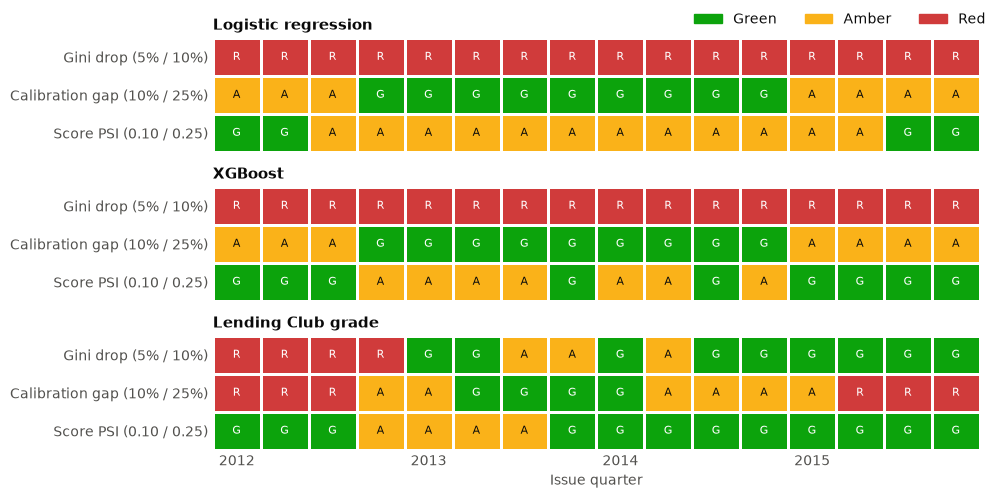

In [5]:
TEST_LABELS = {
    "gini": "Gini drop (5% / 10%)",
    "calibration": "Calibration gap (10% / 25%)",
    "psi": "Score PSI (0.10 / 0.25)",
}
light_code = {"green": 0, "amber": 1, "red": 2}
light_cmap = ListedColormap([LIGHT_COLORS[light] for light in light_code])

fig, axes = plt.subplots(3, 1, figsize=(10, 5), sharex=True)
for ax, model in zip(axes, MODEL_NAMES):
    lights = results[results["model"] == model].set_index("issue_quarter")[[f"{test}_light" for test in THRESHOLDS]].T
    ax.pcolormesh(lights.apply(lambda row: row.map(light_code)), cmap=light_cmap, vmin=-0.5, vmax=2.5,
                  edgecolors="white", linewidth=2)
    for row, test in enumerate(lights.index):
        for column, light in enumerate(lights.loc[test]):
            ax.text(column + 0.5, row + 0.5, light[0].upper(), ha="center", va="center", fontsize=8,
                    color=INK if light == "amber" else "white")
    ax.invert_yaxis()
    ax.set_yticks([0.5, 1.5, 2.5], TEST_LABELS.values())
    ax.set_title(MODEL_LABELS[model])
    ax.grid(False)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
label_quarters(axes[-1], quarters, offset=0.5)
axes[-1].set_xlabel("Issue quarter")
fig.legend(handles=[Patch(color=LIGHT_COLORS[light], label=light.capitalize()) for light in light_code],
           loc="upper right", ncol=3)
fig.tight_layout()
fig.savefig(FIGURES / "traffic_lights.png")

## 5. Figure: Gini over time

One panel per model, same vertical scale. The band is the 95% bootstrap interval of each quarter; the horizontal lines are the Gini at development and the amber and red thresholds derived from it.

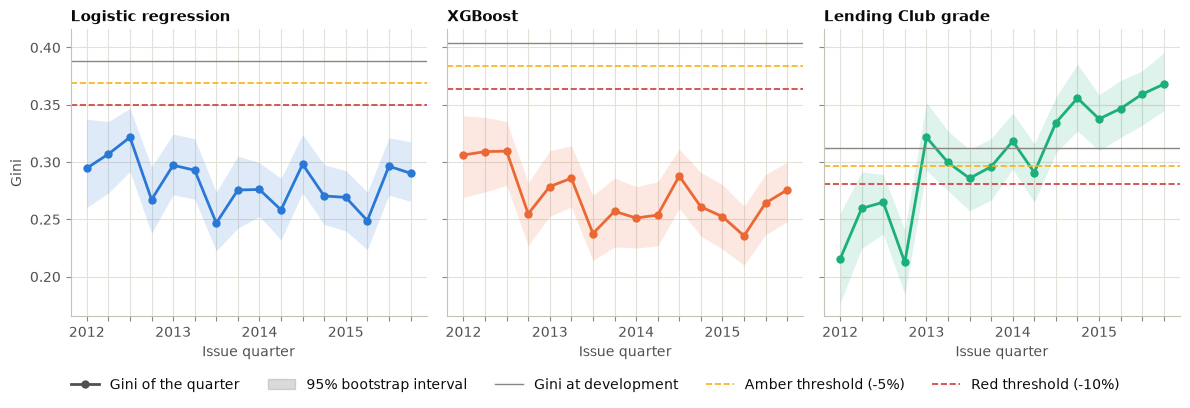

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, model in zip(axes, MODEL_NAMES):
    data = results[results["model"] == model]
    x = range(len(data))
    gini_reference = reference.loc[model, "gini"]
    ax.fill_between(x, data["gini_low"], data["gini_high"], color=MODEL_COLORS[model], alpha=0.15, linewidth=0)
    ax.plot(x, data["gini"], color=MODEL_COLORS[model], marker="o")
    ax.axhline(gini_reference, color=INK_MUTED, linewidth=1)
    ax.axhline(gini_reference * (1 - THRESHOLDS["gini"][0]), color=LIGHT_COLORS["amber"], linewidth=1.2, linestyle="--")
    ax.axhline(gini_reference * (1 - THRESHOLDS["gini"][1]), color=LIGHT_COLORS["red"], linewidth=1.2, linestyle="--")
    ax.set_title(MODEL_LABELS[model])
    ax.set_xlabel("Issue quarter")
    label_quarters(ax, quarters)
axes[0].set_ylabel("Gini")
fig.legend(handles=[
    Line2D([], [], color=INK_SOFT, marker="o", label="Gini of the quarter"),
    Patch(color=INK_MUTED, alpha=0.3, label="95% bootstrap interval"),
    Line2D([], [], color=INK_MUTED, linewidth=1, label="Gini at development"),
    Line2D([], [], color=LIGHT_COLORS["amber"], linewidth=1.2, linestyle="--", label="Amber threshold (-5%)"),
    Line2D([], [], color=LIGHT_COLORS["red"], linewidth=1.2, linestyle="--", label="Red threshold (-10%)"),
], loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
fig.savefig(FIGURES / "gini_over_time.png")

## 6. Figure: calibration over time

The observed default rate of each cohort against the mean PD of the three models. A model is calibrated when its line stays on the observed one.

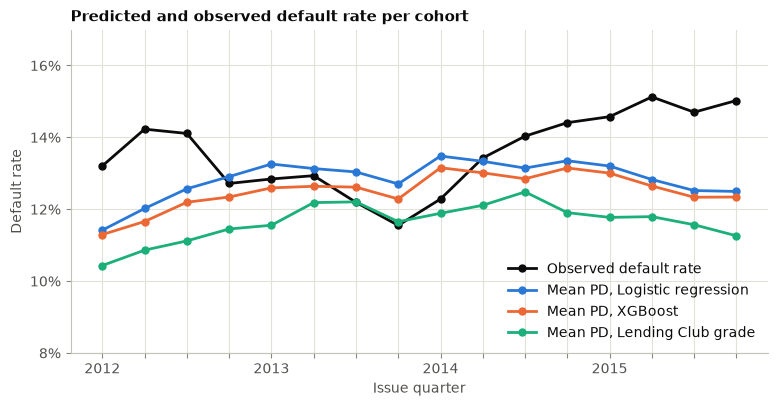

In [7]:
observed = results[results["model"] == MODEL_NAMES[0]]
x = range(len(observed))

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(x, observed["default_rate"], color=INK, marker="o", label="Observed default rate")
for model in MODEL_NAMES:
    data = results[results["model"] == model]
    ax.plot(x, data["mean_pd"], color=MODEL_COLORS[model], marker="o", label=f"Mean PD, {MODEL_LABELS[model]}")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0.08, 0.17)
ax.set_xlabel("Issue quarter")
ax.set_ylabel("Default rate")
ax.set_title("Predicted and observed default rate per cohort")
label_quarters(ax, quarters)
ax.legend(loc="lower right")
fig.savefig(FIGURES / "calibration_over_time.png")

## 7. PSI of every feature

The same index, computed on each input instead of the score, against all the development loans. It shows **which** characteristics of the borrowers moved, and it is the starting point of stage 5.

Unlike the Gini and the calibration, the PSI needs no outcome: it can be computed the day a cohort is issued, three years before its defaults are known. This is why it matters as an early warning.

In [8]:
development = loans[loans["issue_year"].isin(DEV_YEARS)]
later = loans[~loans["issue_year"].isin(DEV_YEARS)]

psi_features = pd.DataFrame({
    quarter: {feature: psi(development[feature], cohort[feature]) for feature in FEATURES}
    for quarter, cohort in later.groupby("issue_quarter")
})
psi_features = psi_features.loc[psi_features.mean(axis=1).sort_values(ascending=False).index]
psi_features.to_csv(PROCESSED / "psi_features.csv", index_label="feature")
psi_features.round(2)

,2012Q1,2012Q2,2012Q3,2012Q4,2013Q1,2013Q2,2013Q3,2013Q4,2014Q1,2014Q2,2014Q3,2014Q4,2015Q1,2015Q2,2015Q3,2015Q4
purpose,0.19,0.13,0.20,0.30,0.46,0.36,0.31,0.52,0.58,0.49,0.46,0.46,0.49,0.48,0.48,0.47
fico,0.04,0.10,0.24,0.36,0.49,0.43,0.40,0.37,0.49,0.45,0.42,0.54,0.52,0.46,0.38,0.39
dti,0.04,0.08,0.28,0.30,0.32,0.24,0.21,0.26,0.30,0.27,0.32,0.40,0.43,0.41,0.42,0.43
log_revol_bal,0.18,0.12,0.19,0.26,0.42,0.29,0.26,0.30,0.26,0.15,0.18,0.18,0.21,0.16,0.17,0.15
revol_util,0.13,0.14,0.19,0.25,0.36,0.27,0.23,0.27,0.28,0.20,0.19,0.20,0.19,0.15,0.15,0.13
open_acc,0.03,0.07,0.15,0.18,0.25,0.18,0.15,0.21,0.22,0.21,0.27,0.20,0.22,0.23,0.24,0.21
loan_amnt,0.14,0.08,0.10,0.17,0.38,0.21,0.17,0.24,0.26,0.16,0.17,0.15,0.21,0.19,0.21,0.16
credit_history_years,0.03,0.01,0.02,0.10,0.12,0.10,0.12,0.18,0.24,0.19,0.19,0.19,0.19,0.18,0.22,0.23
pub_rec,0.01,0.02,0.01,0.02,0.03,0.07,0.09,0.08,0.23,0.22,0.17,0.18,0.19,0.19,0.19,0.19
emp_length_years,0.03,0.05,0.07,0.10,0.12,0.14,0.14,0.13,0.14,0.12,0.11,0.12,0.11,0.11,0.12,0.13


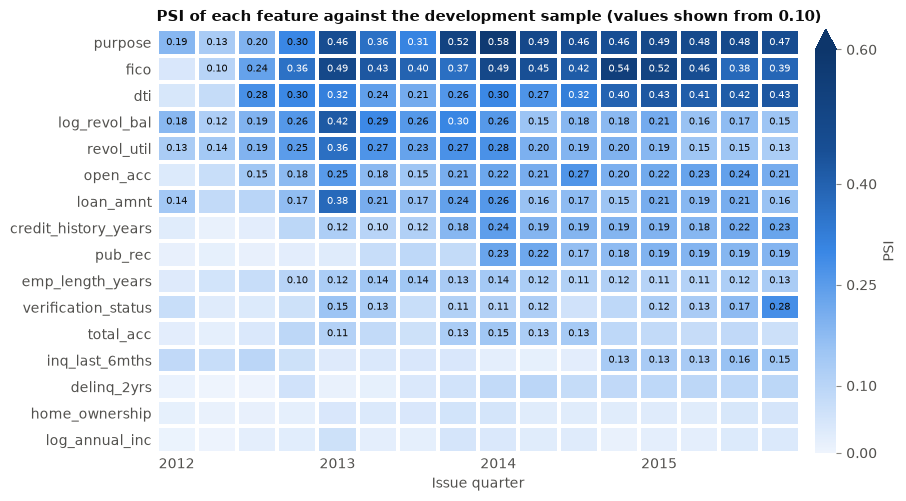

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.5))
mesh = ax.pcolormesh(psi_features, cmap=BLUES, vmin=0, vmax=0.6, edgecolors="white", linewidth=1.5)
# Only the cells above the amber threshold are labelled, to keep the figure readable.
for row, feature in enumerate(psi_features.index):
    for column, value in enumerate(psi_features.loc[feature]):
        if value >= THRESHOLDS["psi"][0]:
            ax.text(column + 0.5, row + 0.5, f"{value:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if value > 0.3 else INK)
ax.invert_yaxis()
ax.set_yticks(np.arange(len(psi_features)) + 0.5, psi_features.index)
label_quarters(ax, quarters, offset=0.5)
ax.set_xlabel("Issue quarter")
ax.set_title("PSI of each feature against the development sample (values shown from 0.10)")
ax.grid(False)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
colorbar = fig.colorbar(mesh, ax=ax, extend="max", ticks=[0, 0.1, 0.25, 0.4, 0.6], pad=0.02)
colorbar.set_label("PSI")
colorbar.outline.set_visible(False)
fig.savefig(FIGURES / "psi_features_heatmap.png")

## 8. Does the complex model age worse?

The side question of the proposal. The Gini of the two models side by side, quarter by quarter, next to their Gini at development.

In [10]:
side_by_side = results.pivot(index="issue_quarter", columns="model", values="gini")[["pd_logit", "pd_xgb"]]
side_by_side["xgb_minus_logit"] = side_by_side["pd_xgb"] - side_by_side["pd_logit"]

print(f"At development: logistic {reference.loc['pd_logit', 'gini']:.3f}, XGBoost {reference.loc['pd_xgb', 'gini']:.3f}")
print(f"Quarters in which XGBoost ranks better than the logistic regression: "
      f"{(side_by_side['xgb_minus_logit'] > 0).sum()} of {len(side_by_side)}")
print(f"Average Gini over the 16 quarters: logistic {side_by_side['pd_logit'].mean():.3f}, "
      f"XGBoost {side_by_side['pd_xgb'].mean():.3f}")
side_by_side.round(3)

At development: logistic 0.388, XGBoost 0.404
Quarters in which XGBoost ranks better than the logistic regression: 2 of 16
Average Gini over the 16 quarters: logistic 0.282, XGBoost 0.270


model,pd_logit,pd_xgb,xgb_minus_logit
issue_quarter,,,
2012Q1,0.295,0.306,0.011
2012Q2,0.307,0.309,0.002
2012Q3,0.322,0.309,-0.012
2012Q4,0.267,0.255,-0.012
2013Q1,0.297,0.279,-0.019
2013Q2,0.293,0.286,-0.007
2013Q3,0.247,0.238,-0.009
2013Q4,0.276,0.257,-0.019
2014Q1,0.276,0.251,-0.025


## 9. What the monitoring says

- **Discrimination fails first, and at once.** Both frozen models are red on the Gini from the first monitored cohort (2012Q1) and stay red in all 16 quarters. The Gini falls from 0.39 (logistic) and 0.40 (XGBoost) at development to 0.25-0.32 and 0.24-0.31, a drop between 17% and 42%. In every quarter the whole bootstrap interval lies below the red threshold, so the red light is not a matter of sampling noise. The reference is itself uncertain (its interval is about ±0.045).
- **Calibration lasts much longer.** It is never red. The two models underestimate risk by 12-22% in the first three quarters of 2012 (amber), are within 10% of the observed default rate from 2012Q4 to 2014Q4 (green), and turn amber again in 2015, when the default rate rises to about 15% while the mean PD stays near 12.5-13%.
- **The score PSI warns without alarming.** It is amber in 12 quarters for the logistic regression and in 7 for XGBoost, never red, although loan purpose, FICO and DTI are red on their own PSI: the shifts of the single features partly cancel out in the score.
- **The complex model starts ahead and ends behind.** XGBoost has the higher Gini at development and in the first two quarters, then the logistic regression ranks better in every later quarter.
- **The lender's own grade recovers.** It is red only in 2012; in 2013 it is back near its development level (green or amber) and from 2014Q3 it is above it, ending at 0.37, higher than both frozen models. It is the only model that was maintained over these years.